## 2. Configuration

In [4]:
# ============================================================
# Main configuration
# ============================================================

DATA_PATH = "C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase3\\final_verified_shopee_dataset.csv"

OUTPUT_DIR = Path("C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase3\\phase3_bilstm_smote_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# Split ratio:
# - test is held out until final evaluation
# - validation is used for config selection / early stopping
TEST_SIZE = 0.20
VAL_SIZE_FROM_TRAINVAL = 0.125  # 0.125 of 80% = 10% total validation

# Text feature extraction
MAX_TFIDF_FEATURES = 20000
N_SVD_COMPONENTS = 256

# Training
PATIENCE = 3
NUM_WORKERS = 0  # keep 0 for Windows/VS Code stability
PIN_MEMORY = True

# Set to True if you only want to test whether the notebook runs quickly.
FAST_DEBUG = False
DEBUG_SAMPLE_SIZE = 1200

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # CUDNN benchmark can make training faster but less deterministic.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)

print("DATA_PATH:", DATA_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())
print("DEVICE:", DEVICE)

DATA_PATH: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\final_verified_shopee_dataset.csv
OUTPUT_DIR: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs
DEVICE: cuda


## 3. Load and validate dataset

In [5]:
df = pd.read_csv(DATA_PATH)

required_cols = ["id", "reviews", "aspects", "sentiments"]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}. Found columns: {df.columns.tolist()}")

df = df[required_cols].copy()

# Basic cleaning
for col in required_cols:
    df[col] = df[col].astype(str).str.strip()

# Remove empty rows
df = df.replace({"": np.nan})
df = df.dropna(subset=["id", "reviews", "aspects", "sentiments"]).copy()

# Normalize sentiment capitalization
df["sentiments"] = df["sentiments"].str.capitalize()

# Your current final dataset should be binary.
# This line makes the notebook robust if an old Neutral row accidentally appears again.
allowed_sentiments = ["Negative", "Positive"]
before_filter = len(df)
df = df[df["sentiments"].isin(allowed_sentiments)].copy()
removed_rows = before_filter - len(df)

# Remove duplicate exact long-format rows
before_duplicates = len(df)
df = df.drop_duplicates(subset=["id", "reviews", "aspects", "sentiments"]).reset_index(drop=True)
duplicate_removed = before_duplicates - len(df)

if FAST_DEBUG and len(df) > DEBUG_SAMPLE_SIZE:
    df = df.sample(DEBUG_SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Unique reviews:", df["id"].nunique())
print("Removed non-binary/invalid sentiment rows:", removed_rows)
print("Removed exact duplicate rows:", duplicate_removed)
print("\nColumns:", df.columns.tolist())
display(df.head())

print("\nSentiment distribution:")
display(df["sentiments"].value_counts())

print("\nAspect distribution:")
display(df["aspects"].value_counts())

Dataset shape: (10781, 4)
Unique reviews: 7577
Removed non-binary/invalid sentiment rows: 0
Removed exact duplicate rows: 0

Columns: ['id', 'reviews', 'aspects', 'sentiments']


,id,reviews,aspects,sentiments
0,2d68668cf8c3d9b8,i hate your ads,App_experience,Negative
1,d363df62267eae48,"Shopee please do not raise the service fee, fr...",Pricing,Negative
2,d363df62267eae48,"Shopee please do not raise the service fee, fr...",Trust,Negative
3,8bdfe8eba767c20d,The most maximal apps have pop ads everywhere.,App_experience,Negative
4,c6e103e312de60a4,"Open the application, and then there's this li...",App_experience,Negative



Sentiment distribution:


sentiments
Negative    8324
Positive    2457
Name: count, dtype: int64


Aspect distribution:


aspects
App_experience              3583
Trust                       3122
Shipping                     936
Delivered_product_status     728
Pricing                      692
Customer_service             484
Item_quality                 381
Payment                      301
Information                  202
Product_features             150
Return_process                88
Product_availability          61
Refund_process                53
Name: count, dtype: int64

## 4. Exploratory visualization for skripsi

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\01_sentiment_distribution_before_smote.png


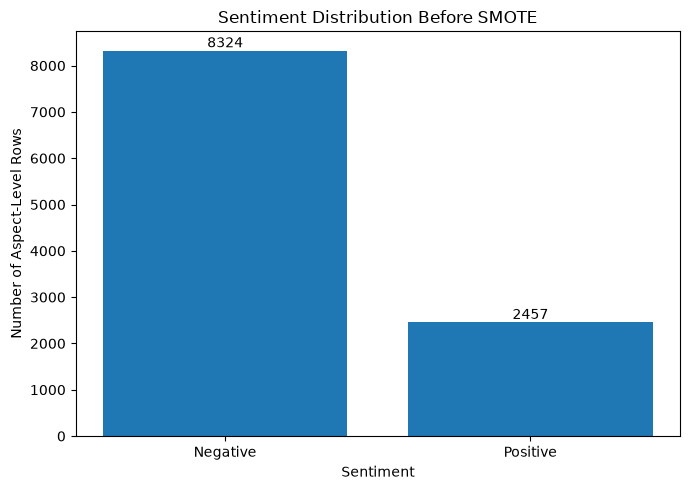

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\02_aspect_distribution.png


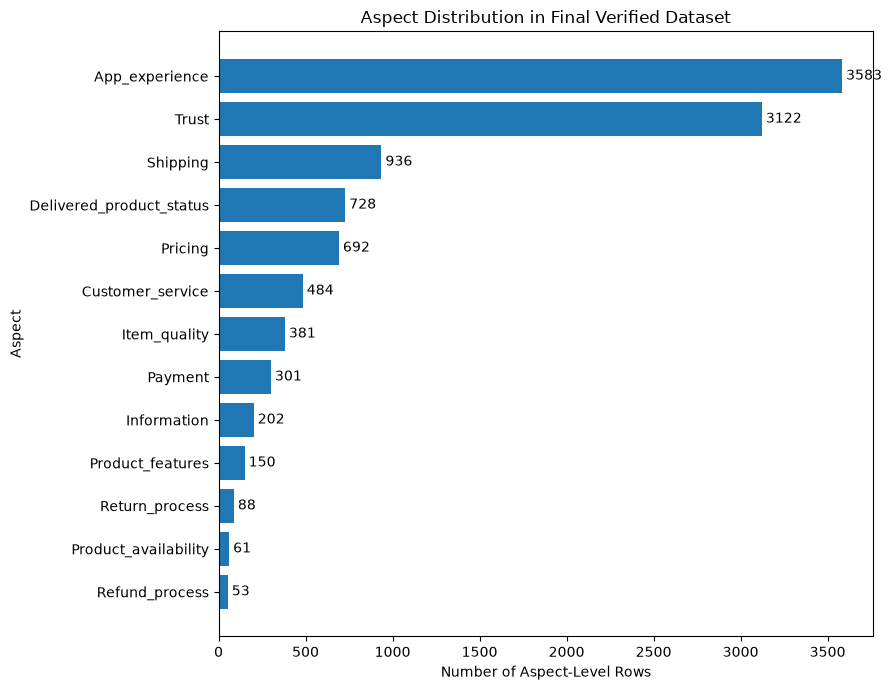

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\03_aspects_per_review_distribution.png


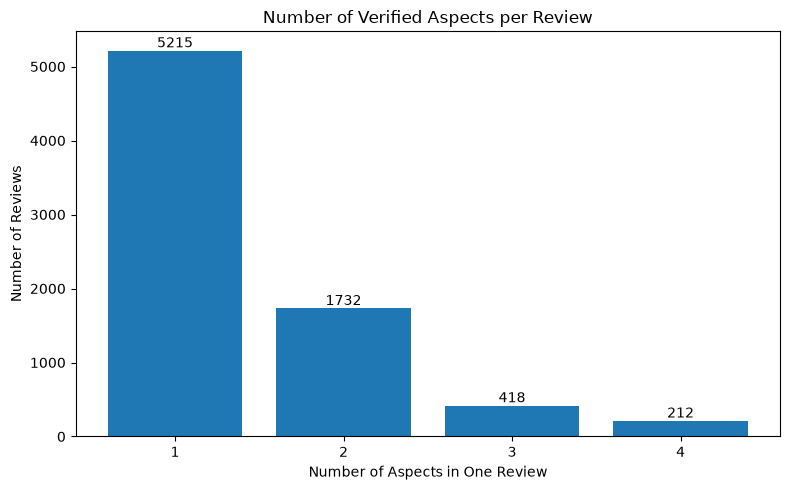

In [6]:
def save_current_fig(filename):
    path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")
    plt.show()

# Sentiment distribution
sent_counts = df["sentiments"].value_counts().reindex(["Negative", "Positive"]).fillna(0)

plt.figure(figsize=(7, 5))
plt.bar(sent_counts.index, sent_counts.values)
plt.title("Sentiment Distribution Before SMOTE")
plt.xlabel("Sentiment")
plt.ylabel("Number of Aspect-Level Rows")
for i, v in enumerate(sent_counts.values):
    plt.text(i, v, str(int(v)), ha="center", va="bottom")
save_current_fig("01_sentiment_distribution_before_smote.png")

# Aspect distribution
aspect_counts = df["aspects"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(9, 7))
plt.barh(aspect_counts.index, aspect_counts.values)
plt.title("Aspect Distribution in Final Verified Dataset")
plt.xlabel("Number of Aspect-Level Rows")
plt.ylabel("Aspect")
for i, v in enumerate(aspect_counts.values):
    plt.text(v, i, f" {int(v)}", va="center")
save_current_fig("02_aspect_distribution.png")

# Review multi-aspect count distribution
review_aspect_counts = df.groupby("id")["aspects"].nunique().value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(review_aspect_counts.index.astype(str), review_aspect_counts.values)
plt.title("Number of Verified Aspects per Review")
plt.xlabel("Number of Aspects in One Review")
plt.ylabel("Number of Reviews")
for i, v in enumerate(review_aspect_counts.values):
    plt.text(i, v, str(int(v)), ha="center", va="bottom")
save_current_fig("03_aspects_per_review_distribution.png")

## 5. Build aspect-aware input text

The aspect is inserted before the review so the BiLSTM knows which aspect sentiment to classify.

In [7]:
df["model_text"] = (
    "[ASPECT] " + df["aspects"].astype(str) +
    " [REVIEW] " + df["reviews"].astype(str)
)

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["sentiments"])

label_mapping = {int(i): label for i, label in enumerate(label_encoder.classes_)}
print("Label mapping:", label_mapping)

with open(OUTPUT_DIR / "label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(label_mapping, f, ensure_ascii=False, indent=2)

display(df[["id", "aspects", "sentiments", "label", "model_text"]].head())

Label mapping: {0: 'Negative', 1: 'Positive'}


,id,aspects,sentiments,label,model_text
0,2d68668cf8c3d9b8,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] i hate your ads
1,d363df62267eae48,Pricing,Negative,0,[ASPECT] Pricing [REVIEW] Shopee please do not...
2,d363df62267eae48,Trust,Negative,0,[ASPECT] Trust [REVIEW] Shopee please do not r...
3,8bdfe8eba767c20d,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] The most maxi...
4,c6e103e312de60a4,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] Open the appl...
